/var/folders/rr/nzkd8wdd7n10znfm1ynvx03r0000gn/T/ipykernel_5570/2876221909.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Top50[years] = Top50[years].apply(


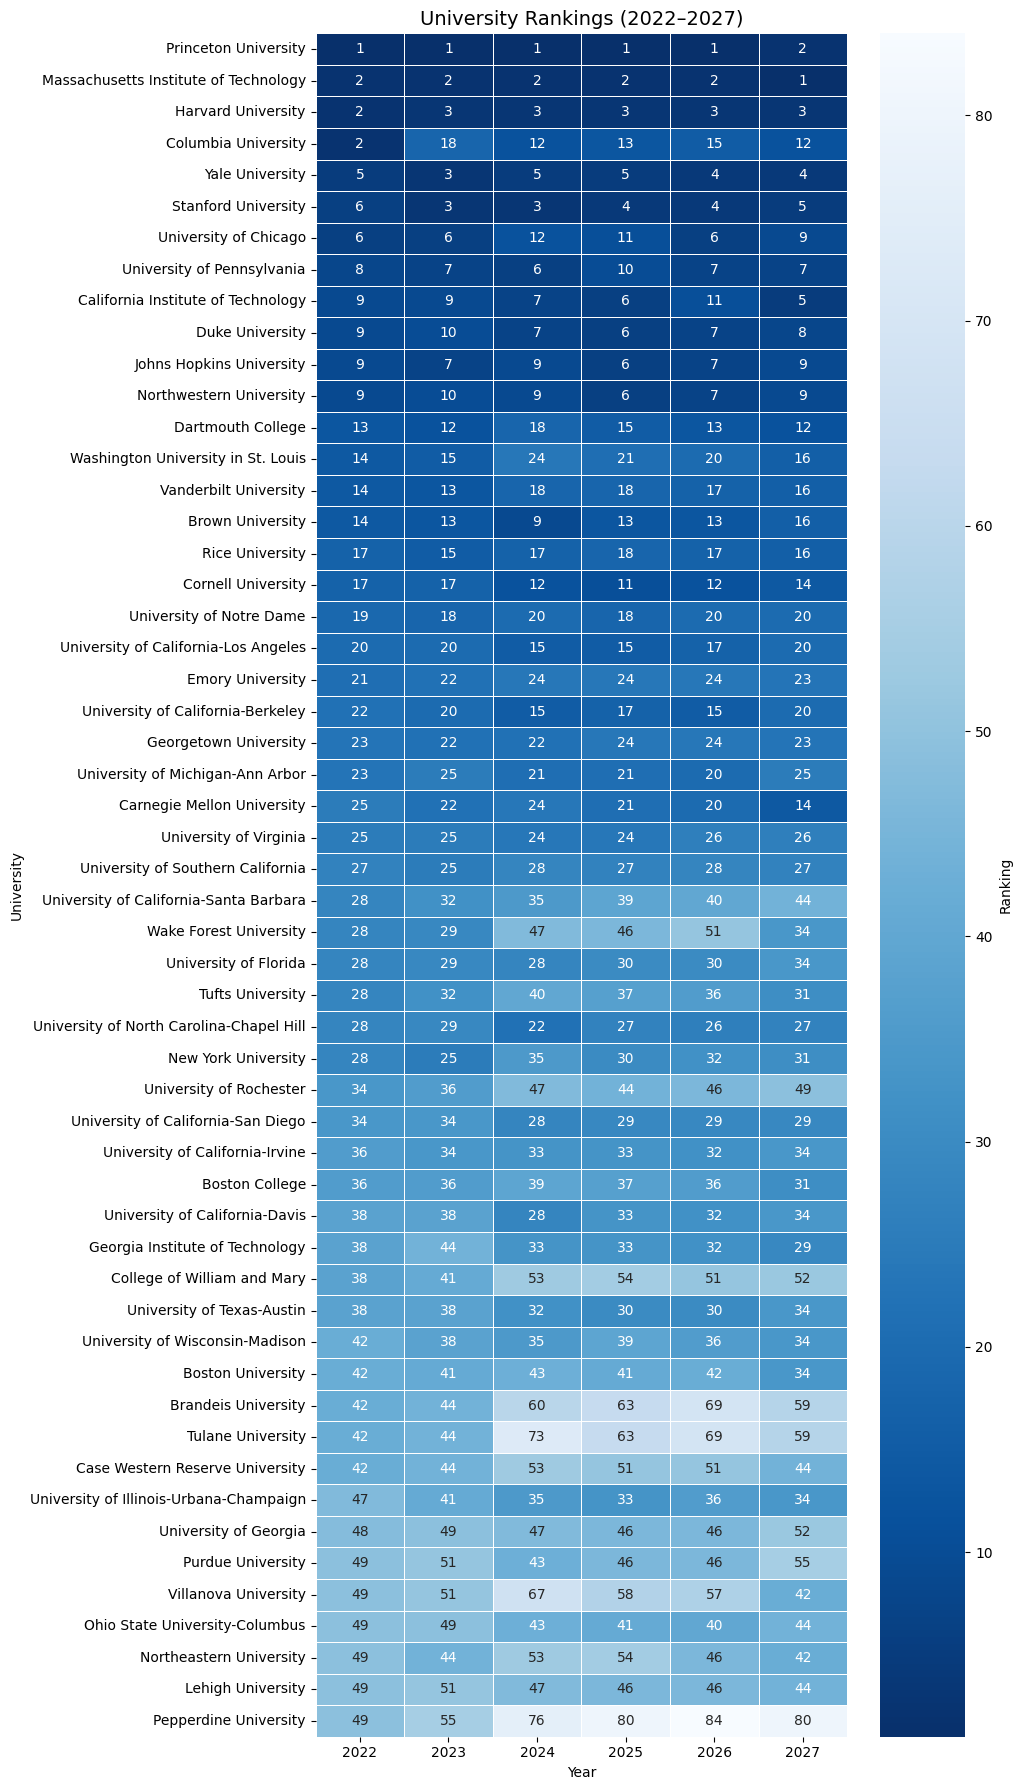

In [ ]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

UniversityRankings = pd.read_csv("UniversityRankings.csv")
#print(UniveristyRankings.head())

UniversityRankings = UniversityRankings[['University Name','2027', '2026', '2025', '2024', '2023', '2022']]

Top50 = UniversityRankings[UniversityRankings['2022'] <= 50]

#There are 6 schools tied for 49 in 2022 so top 54 schools were taken into account 
#print((Top50['2022'] == 49).sum())

#Converts all numbers to integers
years = ['2022', '2023', '2024', '2025', '2026', '2027']
Top50[years] = Top50[years].apply(
    pd.to_numeric, errors='coerce'
).astype('Int64')


heatmap_data = Top50[['University Name'] + years].copy()
heatmap_data = heatmap_data.sort_values('2022')
heatmap_data = heatmap_data.set_index('University Name')
heatmap_data = heatmap_data.astype(float)

#print(heatmap_data.dtypes)

plt.figure(figsize=(10, 18))

ax = sns.heatmap(
    heatmap_colors,
    annot=labels.to_numpy(),
    fmt='',
    cmap='RdYlGn_r',
    vmin=1,
    vmax=50,
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Ranking'}
)
ax.set_facecolor('lightgrey')
plt.title('University Rankings (2022–2027)', fontsize=14)
plt.xlabel('Year')
plt.ylabel('University')
plt.yticks(rotation=0)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()





